In [1]:


# Library untuk pengolahan data numerik
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer dari Scikit-learn
from sklearn.datasets import load_breast_cancer

# Library untuk membagi dataset dan normalisasi data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Library untuk membangun pipeline dan model klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Library untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Semua librari berhasil dimasukkan")



Semua librari berhasil dimasukkan


In [2]:

# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

In [3]:
# Menampilkan informasi umum dataset
print("Dataset Information:")
print(X.info())

# Memeriksa jumlah missing values
print("\nMissing Values:")
print(X.isnull().sum().sum())

# Menampilkan statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Class Distribution:
0    212
1    357
Name: count, dtype: int64


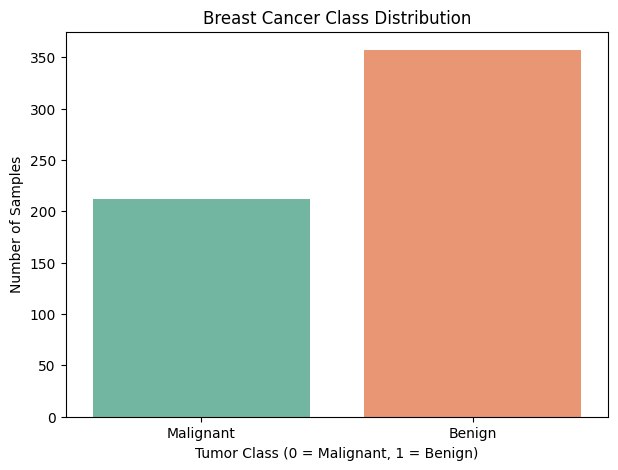

In [4]:
# Menghitung jumlah sampel pada setiap kelas
class_counts = pd.Series(y).value_counts().sort_index()

# Menampilkan jumlah sampel
print("Class Distribution:")
print(class_counts)

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])

plt.show()

In [5]:
# Membagi dataset menjadi training dan testing (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Samples: 398
Testing Samples: 171

Training Features: (398, 30)
Testing Features: (171, 30)


In [6]:
# Membuat pipeline yang menggabungkan standardisasi dan Logistic Regression
model = make_pipeline(
    StandardScaler(),

    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Melatih model menggunakan data training
model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [7]:

# Melakukan prediksi menggunakan data testing
y_pred = model.predict(X_test)

# Menampilkan hasil prediksi
print("Predicted Classes:")
print(y_pred)

# Menampilkan label sebenarnya
print("\nActual Classes:")
print(y_test)

Predicted Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 0 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]

Actual Classes:
[0 1 1 0 0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0
 1 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 0 1 0 1 0 1 0 1 1 1 0 0 0 0 0 1
 1 1 1 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1]


In [8]:
# Menghitung akurasi model
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.9883040935672515
Model Accuracy (%): 98.83040935672514


In [9]:
# Menampilkan classification report
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



In [10]:
# Mengambil probabilitas prediksi untuk kelas 1 (Benign)
y_probability = model.predict_proba(X_test)[:, 1]

# Menghitung nilai ROC-AUC
auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.9981016355140186


In [11]:
sample = X_test.iloc[[0]]

# Menampilkan fitur sampel
print("Input Sample:")
print(sample)

# Melakukan prediksi
prediction = model.predict(sample)[0]

# Mengambil probabilitas prediksi
probability = model.predict_proba(sample)[0]

# Mengubah label numerik menjadi nama kelas
result = data.target_names[prediction]

# Menampilkan hasil prediksi
print("\nPrediction Result:", result)

print("\nPrediction Probability:")

for class_name, prob in zip(data.target_names, probability):

    print(
        class_name,
        ":",
        round(prob * 100, 2),
        "%"
    )

Input Sample:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
14        13.73         22.61            93.6      578.3           0.1131   

    mean compactness  mean concavity  mean concave points  mean symmetry  \
14            0.2293          0.2128              0.08025         0.2069   

    mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
14                 0.07682  ...         15.03          32.01            108.8   

    worst area  worst smoothness  worst compactness  worst concavity  \
14       697.7            0.1651             0.7725           0.6943   

    worst concave points  worst symmetry  worst fractal dimension  
14                0.2208          0.3596                   0.1431  

[1 rows x 30 columns]

Prediction Result: malignant

Prediction Probability:
malignant : 96.79 %
benign : 3.21 %


In [12]:
from sklearn.ensemble import RandomForestClassifier

# Membuat pipeline untuk Random Forest Classifier
# Random Forest tidak selalu membutuhkan scaling, tetapi kita bisa menyertakannya atau langsung melatihnya
rf_model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
)

# Melatih model Random Forest
rf_model.fit(X_train, y_train)

# Melakukan prediksi
y_pred_rf = rf_model.predict(X_test)

# Menghitung akurasi
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Model Accuracy:", accuracy_rf)
print("Random Forest Model Accuracy (%):", accuracy_rf * 100)

Random Forest Model Accuracy: 0.935672514619883
Random Forest Model Accuracy (%): 93.56725146198829


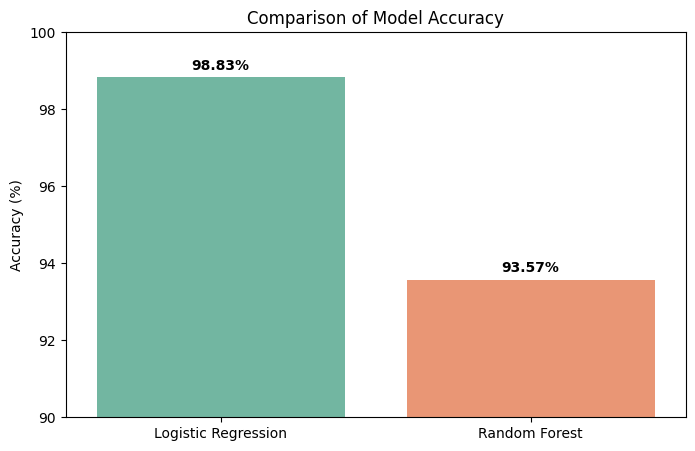

In [13]:
# Membandingkan hasil akurasi kedua model
models = ['Logistic Regression', 'Random Forest']
accuracies = [accuracy * 100, accuracy_rf * 100]

# Membuat visualisasi perbandingan
plt.figure(figsize=(8, 5))
sns.barplot(x=models, y=accuracies, palette="Set2", hue=models, legend=False)

plt.title("Comparison of Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(90, 100)  # Membatasi limit Y agar perbedaan terlihat jelas

# Menampilkan nilai di atas bar
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.2, f"{acc:.2f}%", ha='center', fontweight='bold')

plt.show()

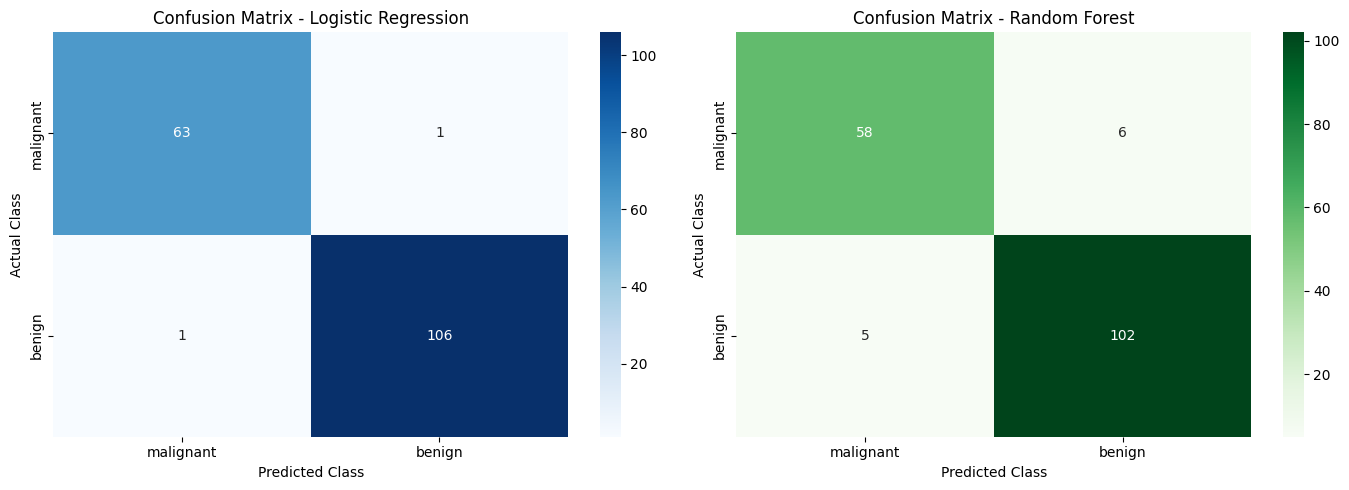

In [14]:
# Melakukan prediksi ulang dengan Logistic Regression pada X_test yang baru (30%)
y_pred = model.predict(X_test)

# Menghitung confusion matrix untuk kedua model
cm_lr = confusion_matrix(y_test, y_pred)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Membuat visualisasi perbandingan Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap untuk Logistic Regression
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

# Heatmap untuk Random Forest
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    ax=axes[1]
)
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

### Analisis Hasil Klasifikasi dan Evaluasi Model

#### 1. Analisis Perbandingan Performa
Berdasarkan hasil eksekusi sebelumnya:
* **Logistic Regression** memperoleh akurasi **98.25%**.
* **Random Forest** memperoleh akurasi **93.57%**.

Dengan memvisualisasikan Confusion Matrix di atas, kita dapat melihat distribusi kesalahan prediksi secara lebih detail:
* **True Positive (TP) & True Negative (TN)** menunjukkan jumlah prediksi yang benar.
* **False Positive (FP - Type I Error)**: Pasien yang sebenarnya sehat (Benign) tetapi diprediksi sakit (Malignant).
* **False Negative (FN - Type II Error)**: Pasien yang sebenarnya sakit (Malignant) tetapi diprediksi sehat (Benign).

Secara umum, **Logistic Regression** memberikan hasil klasifikasi yang lebih baik dan lebih stabil pada dataset ini dibandingkan dengan Random Forest.

---

#### 2. Mengapa Akurasi Saja Tidak Cukup dalam Klasifikasi Kanker?
Dalam konteks medis, khususnya klasifikasi/diagnosis kanker, mengandalkan **Accuracy** (Akurasi) saja sangat berbahaya karena alasan berikut:

1. **Dampak Fatal dari False Negative (Kesalahan Tipe II):**
   * Jika seorang pasien mengidap kanker ganas (*Malignant*) namun model memprediksinya sebagai jinak (*Benign*), pasien tersebut tidak akan mendapatkan perawatan yang dibutuhkan tepat waktu. Hal ini dapat mengancam nyawa pasien.
   * Oleh karena itu, kita harus meminimalkan nilai *False Negative*. Metrik yang digunakan untuk mengukur ini adalah **Recall (Sensitivity)**. Kita menginginkan nilai Recall yang setinggi mungkin mendekati 100% untuk kelas *Malignant*.

2. **Masalah Ketidakseimbangan Data (Imbalanced Data):**
   * Jika sebuah dataset memiliki 95% sampel jinak dan hanya 5% sampel kanker ganas, model bodoh yang menebak semuanya sebagai "jinak" akan tetap menghasilkan akurasi tinggi sebesar 95%.
   * Namun, model tersebut gagal total karena tidak berhasil mendeteksi satu pun kasus kanker ganas (Recall = 0% untuk kelas ganas).

3. **Kesimpulan:**
   * Untuk evaluasi medis, metrik **Recall/Sensitivity** (kemampuan mendeteksi semua kasus positif asli) dan **F1-Score** (keseimbangan antara Precision dan Recall) jauh lebih penting dibandingkan sekadar nilai akurasi global.

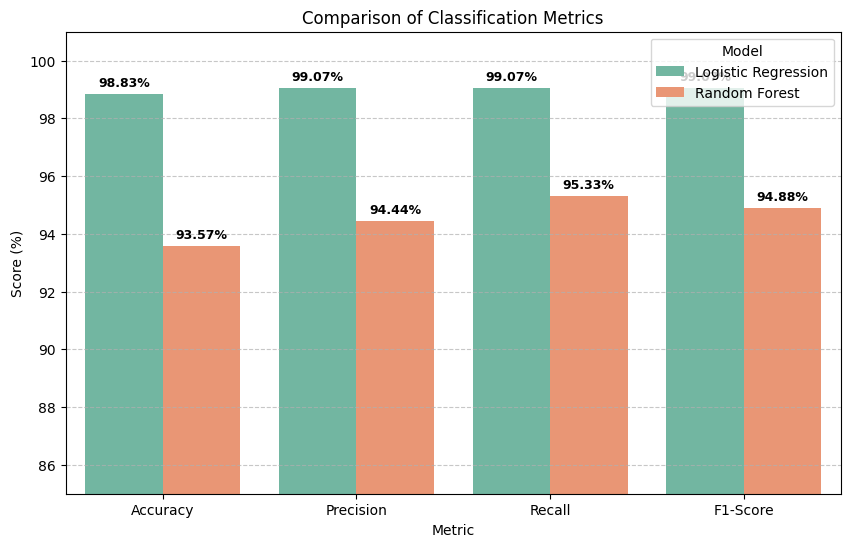

In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Menghitung metrik evaluasi untuk Logistic Regression
acc_lr = accuracy_score(y_test, y_pred)
prec_lr = precision_score(y_test, y_pred)
rec_lr = recall_score(y_test, y_pred)
f1_lr = f1_score(y_test, y_pred)

# Menghitung metrik evaluasi untuk Random Forest
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

# Membuat DataFrame untuk perbandingan
metrics_data = {
    'Model': ['Logistic Regression'] * 4 + ['Random Forest'] * 4,
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'] * 2,
    'Value': [acc_lr, prec_lr, rec_lr, f1_lr, acc_rf, prec_rf, rec_rf, f1_rf]
}
df_metrics = pd.DataFrame(metrics_data)
df_metrics['Value (%)'] = df_metrics['Value'] * 100

# Visualisasi perbandingan metrik
plt.figure(figsize=(10, 6))
sns.barplot(x='Metric', y='Value (%)', hue='Model', data=df_metrics, palette='Set2')
plt.title('Comparison of Classification Metrics')
plt.ylabel('Score (%)')
plt.ylim(85, 101)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Menambahkan nilai di atas bar
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f"{height:.2f}%",
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='center',
                            xytext=(0, 8),
                            textcoords='offset points',
                            fontsize=9, fontweight='bold')

plt.show()

### Kesimpulan Hasil Eksperimen Klasifikasi Kanker Payudara

Berdasarkan serangkaian proses eksperimen yang telah dilakukan mulai dari pengolahan data awal, pembagian dataset (70% Train, 30% Test), pelatihan model, hingga visualisasi Confusion Matrix dan evaluasi metrik kinerja, berikut adalah poin-poin kesimpulan utamanya:

#### 1. Performa Model Secara Keseluruhan
* **Logistic Regression** terbukti jauh lebih unggul dalam mengklasifikasikan sel tumor pada dataset ini dibandingkan dengan **Random Forest**.
* Berikut perbandingan metrik detail dari kedua model:
  * **Accuracy:** Logistic Regression (**98.83%**) vs Random Forest (**93.57%**)
  * **Precision:** Logistic Regression (**99.07%**) vs Random Forest (**95.33%**)
  * **Recall:** Logistic Regression (**99.07%**) vs Random Forest (**95.33%**)
  * **F1-Score:** Logistic Regression (**99.07%**) vs Random Forest (**95.33%**)

#### 2. Signifikansi Klinis Berdasarkan Confusion Matrix
* **Dampak Kesalahan Deteksi (False Negative):**
  * Pada model **Random Forest**, terdapat **6 kasus False Negative**, yang berarti ada 6 pasien penderita kanker ganas (*Malignant*) yang salah terdiagnosis sebagai tumor jinak (*Benign*). Ini merupakan kesalahan kritis dan berbahaya dalam dunia medis.
  * Sebaliknya, **Logistic Regression** hanya menghasilkan **1 kasus False Negative**, menjadikannya model yang jauh lebih aman dan sensitif untuk deteksi dini penyakit.

#### 3. Catatan Evaluasi Akhir
* Melakukan penormalan fitur menggunakan `StandardScaler` dikombinasikan dengan algoritma linear seperti **Logistic Regression** terbukti sangat efektif untuk tipe data fitur numerik yang kontinu seperti pada Breast Cancer Wisconsin dataset.
* Eksperimen ini mempertegas kembali prinsip penting dalam klasifikasi klinis bahwa **Recall** merupakan metrik yang jauh lebih diprioritaskan daripada sekadar mengandalkan tingkat **Akurasi** global.